In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean styling
sns.set_theme(style="whitegrid")

# Load your verified, clean Parquet data
df = pd.read_parquet("data/processed/healthcare_clean.parquet")
print(f"Dataset Loaded Successfully! Records: {len(df):,}")
df.info()

Dataset Loaded Successfully! Records: 55,392
<class 'pandas.DataFrame'>
RangeIndex: 55392 entries, 0 to 55391
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Age                  55392 non-null  int64         
 1   Gender               55392 non-null  str           
 2   Blood Type           55392 non-null  str           
 3   Medical Condition    55392 non-null  str           
 4   Date of Admission    55392 non-null  datetime64[us]
 5   Doctor               55392 non-null  str           
 6   Hospital             55392 non-null  str           
 7   Insurance Provider   55392 non-null  str           
 8   Billing Amount       55392 non-null  float64       
 9   Room Number          55392 non-null  int64         
 10  Admission Type       55392 non-null  str           
 11  Discharge Date       55392 non-null  datetime64[us]
 12  Medication           55392 non-null  str           
 1

,Total_Patients,Mean_LOS,Median_LOS,P90_LOS,Max_LOS
Medical Condition,,,,,
Asthma,9167,15.70,16.0,28.0,30
Arthritis,9297,15.52,15.0,27.0,30
Cancer,9208,15.50,15.0,28.0,30
Hypertension,9224,15.46,15.0,27.0,30
Obesity,9212,15.46,15.0,27.0,30
Diabetes,9284,15.42,15.0,27.0,30


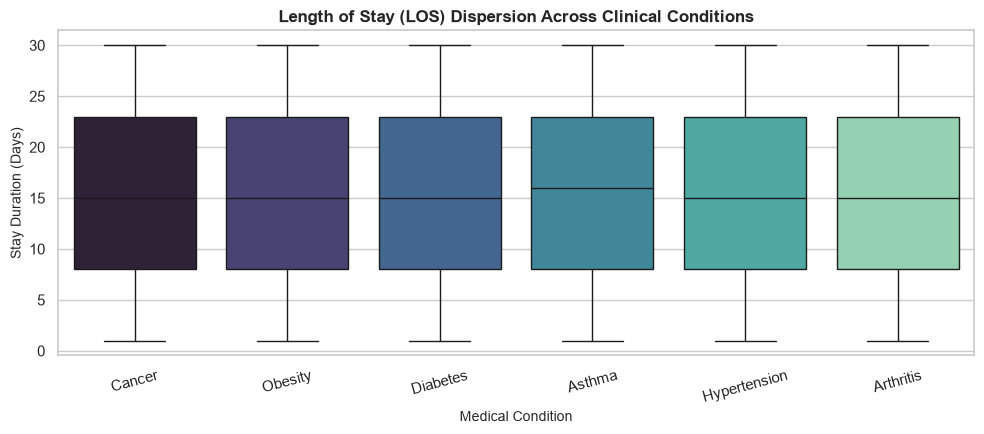

In [2]:
# 1. Summary table by Medical Condition
los_summary = df.groupby("Medical Condition")["Length_of_Stay_Days"].agg(
    Total_Patients="count",
    Mean_LOS="mean",
    Median_LOS="median",
    P90_LOS=lambda x: np.percentile(x, 90),
    Max_LOS="max"
).round(2).sort_values(by="Mean_LOS", ascending=False)

display(los_summary)

# 2. Distribution Plot
plt.figure(figsize=(10, 4.5))
sns.boxplot(
    data=df, 
    x="Medical Condition", 
    y="Length_of_Stay_Days", 
    palette="mako", 
    hue="Medical Condition", 
    legend=False
)
plt.title("Length of Stay (LOS) Dispersion Across Clinical Conditions", fontsize=12, fontweight="bold")
plt.xlabel("Medical Condition", fontsize=10)
plt.ylabel("Stay Duration (Days)", fontsize=10)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Admission Type,Elective,Emergency,Urgent
Insurance Provider,,,
Aetna,1660.59,1643.36,1734.58
Blue Cross,1668.59,1646.38,1654.26
Cigna,1705.83,1581.58,1652.97
Medicare,1657.66,1616.60,1613.33
UnitedHealthcare,1631.67,1684.72,1645.05


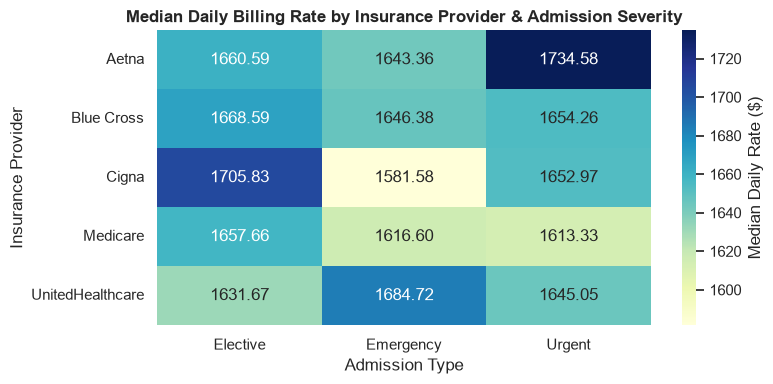

In [3]:
# Aggregate daily billing rate across Insurance Providers and Admission Types
billing_pivot = df.pivot_table(
    index="Insurance Provider",
    columns="Admission Type",
    values="Daily_Billing_Rate",
    aggfunc="median"
).round(2)

display(billing_pivot)

# Heatmap Visualization
plt.figure(figsize=(8, 4))
sns.heatmap(billing_pivot, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Median Daily Rate ($)'})
plt.title("Median Daily Billing Rate by Insurance Provider & Admission Severity", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

In [4]:
# 1. Medication protocol matrix by Medical Condition
med_matrix = pd.crosstab(
    df["Medical Condition"], 
    df["Medication"], 
    normalize="index"
).round(4) * 100

print("Medication Distribution (% within Condition):")
display(med_matrix)

# 2. Billing impact by Test Result
test_billing = df.groupby(["Medical Condition", "Test Results"])["Billing Amount"].agg(
    Avg_Bill="mean",
    Median_Bill="median"
).round(2).unstack()

print("\nBilling Amount by Condition & Diagnostic Test Result:")
display(test_billing)

Medication Distribution (% within Condition):


Medication,Aspirin,Ibuprofen,Lipitor,Paracetamol,Penicillin
Medical Condition,,,,,
Arthritis,20.62,19.59,19.61,20.16,20.03
Asthma,19.61,19.90,19.83,20.57,20.08
Cancer,19.37,20.24,20.85,20.10,19.43
Diabetes,19.97,20.02,20.34,19.47,20.20
Hypertension,20.16,20.47,19.98,20.01,19.37
Obesity,20.19,20.08,19.83,19.38,20.52



Billing Amount by Condition & Diagnostic Test Result:


Avg_Bill                        Median_Bill               \
Test Results       Abnormal Inconclusive    Normal    Abnormal Inconclusive   
Medical Condition                                                             
Arthritis          25570.16     25312.71  25703.69    25636.35     25171.53   
Asthma             25535.68     25901.59  25624.20    25519.97     26035.76   
Cancer             25179.04     25183.83  25282.80    25008.04     24793.19   
Diabetes           25744.87     25918.34  25422.96    25775.87     25773.33   
Hypertension       25656.66     25939.27  25083.30    25460.63     26207.59   
Obesity            25859.77     25843.53  25877.58    26366.59     26037.85   

                             
Test Results         Normal  
Medical Condition            
Arthritis          25802.99  
Asthma             25564.37  
Cancer             25093.83  
Diabetes           25334.74  
Hypertension       24396.72  
Obesity            26148.16

In [5]:
# Cell 5: Executive Metrics Export
executive_summary = df.groupby(["Medical Condition", "Admission Type"]).agg(
    Patient_Volume=("Patient_ID", "count"),
    Avg_Stay_Days=("Length_of_Stay_Days", "mean"),
    Median_Daily_Cost=("Daily_Billing_Rate", "median"),
    Total_Revenue=("Billing Amount", "sum")
).round(2)

# Save summary metrics to parquet for downstream reporting
executive_summary.to_parquet("data/processed/executive_operational_summary.parquet")
print("Executive operational metrics serialized to 'data/processed/executive_operational_summary.parquet'!")
display(executive_summary.head(10))

Executive operational metrics serialized to 'data/processed/executive_operational_summary.parquet'!


Patient_Volume  Avg_Stay_Days  \
Medical Condition Admission Type                                  
Arthritis         Elective                  3079          15.63   
                  Emergency                 3105          15.51   
                  Urgent                    3113          15.41   
Asthma            Elective                  3097          15.74   
                  Emergency                 2997          15.58   
                  Urgent                    3073          15.77   
Cancer            Elective                  3142          15.27   
                  Emergency                 3010          16.00   
                  Urgent                    3056          15.26   
Diabetes          Elective                  3053          15.61   

                                  Median_Daily_Cost  Total_Revenue  
Medical Condition Admission Type                                    
Arthritis         Elective                  1643.90    78439430.13  
                  Emergency                 1609.60    79301653.38  
                  Urgent                    1676.08    79593883.93  
Asthma            Elective                  1661.74    78302515.79  
                  Emergency                 1643.84    77688263.52  
                  Urgent                    1618.71    79478891.74  
Cancer            Elective                  1660.32    80903453.37  
                  Emergency                 1555.30    74961713.16  
                  Urgent                    1634.46    76313697.75  
Diabetes          Elective                  1684.15    79457410.14